In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.rates import simulate_vasicek
from src.swap import par_swap_rate, simulate_swap_mtm
from src.exposure import expected_exposure, potential_future_exposure, expected_positive_exposure

In [2]:
# Vasicek y simulación
r0, a, b, sigma = 0.03, 0.5, 0.04, 0.01
T, n_steps, n_paths = 5, 60, 10_000
times, rates = simulate_vasicek(r0, a, b, sigma, T, n_steps, n_paths, seed=42)

# Swap
maturity, freq, notional = 5, 2, 1_000_000
K = par_swap_rate(r0, a, b, sigma, maturity, freq)

mtm = simulate_swap_mtm(times, rates, a, b, sigma, K, maturity, freq, notional)
print(f"K = {K:.4%} | shape MtM = {mtm.shape}")

K = 3.6441% | shape MtM = (10000, 61)


In [3]:
ee = expected_exposure(mtm)
pfe95 = potential_future_exposure(mtm, 0.95)
pfe99 = potential_future_exposure(mtm, 0.99)
epe = expected_positive_exposure(ee)

i_max = pfe95.argmax()
print(f"EE máxima:     {ee.max():,.0f}  (año {times[ee.argmax()]:.2f})")
print(f"PFE 95% máx.:  {pfe95.max():,.0f}  (año {times[i_max]:.2f})")
print(f"PFE 99% máx.:  {pfe99.max():,.0f}")
print(f"EPE:           {epe:,.0f}")

EE máxima:     9,740  (año 2.42)
PFE 95% máx.:  32,622  (año 2.42)
PFE 99% máx.:  44,622
EPE:           6,489


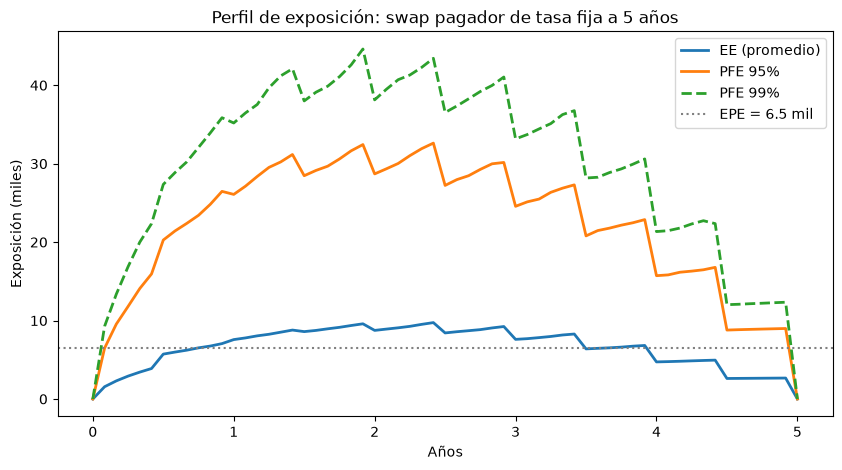

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, ee / 1_000, lw=2, label="EE (promedio)")
ax.plot(times, pfe95 / 1_000, lw=2, label="PFE 95%")
ax.plot(times, pfe99 / 1_000, lw=2, ls="--", label="PFE 99%")
ax.axhline(epe / 1_000, color="gray", ls=":", label=f"EPE = {epe/1_000:,.1f} mil")
ax.set_xlabel("Años")
ax.set_ylabel("Exposición (miles)")
ax.set_title("Perfil de exposición: swap pagador de tasa fija a 5 años")
ax.legend()
fig.savefig("../reports/figures/exposure_profile.png", dpi=150, bbox_inches="tight")
plt.show()

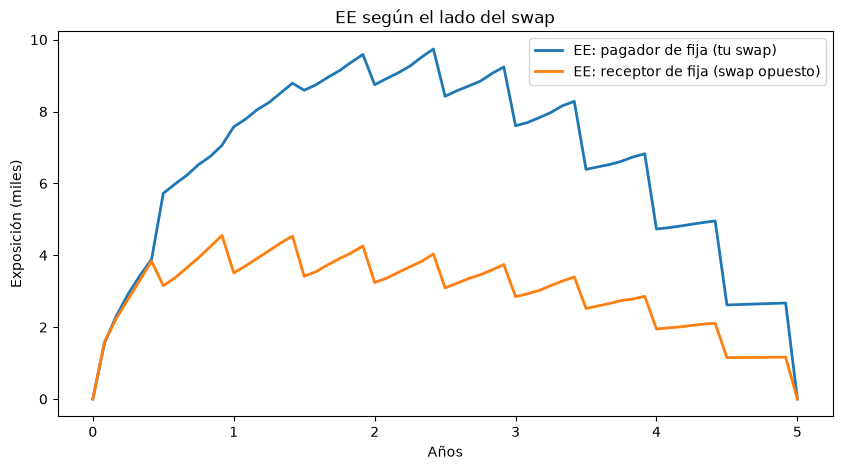

In [5]:
ee_receiver = expected_exposure(-mtm)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, ee / 1_000, lw=2, label="EE: pagador de fija (tu swap)")
ax.plot(times, ee_receiver / 1_000, lw=2, label="EE: receptor de fija (swap opuesto)")
ax.set_xlabel("Años")
ax.set_ylabel("Exposición (miles)")
ax.set_title("EE según el lado del swap")
ax.legend()
plt.show()